## 1. Las lecturas meteorológicas originales

Partimos del fichero ya corregido por el notebook de desfase (`db_meteorologica_sinDesfase.csv.gz`). Son lecturas de 12 estaciones repartidas por la isla, una cada 5 minutos, con ocho variables meteorológicas. Recordamos que son datos simulados por la asignatura, no medidas reales.

In [2]:
lect = pd.read_csv(LECTURAS)
lect["timestamp"] = pd.to_datetime(lect["timestamp"], utc=True)
lect["estacion"] = lect["station_id"].map(NOMBRES)

VARIABLES = ["temperature_c", "humidity_pct", "wind_speed_kmh", "wind_direction_deg",
             "pressure_hpa", "precipitation_mm", "visibility_km", "uv_index"]

# Huecos: comparamos los instantes que hay con los que debería haber cada 5 minutos
instantes = lect["timestamp"].drop_duplicates().sort_values()
esperados = pd.date_range(instantes.min(), instantes.max(), freq="5min")
faltan = esperados.difference(instantes)

resumen = pd.Series({
    "Filas": len(lect),
    "Estaciones": lect["station_id"].nunique(),
    "Desde": instantes.min().strftime("%Y-%m-%d %H:%M"),
    "Hasta": instantes.max().strftime("%Y-%m-%d %H:%M"),
    "Lecturas duplicadas": int(lect.duplicated(["station_id", "timestamp"]).sum()),
    "Valores nulos": int(lect[VARIABLES].isna().sum().sum()),
    "Instantes sin datos": len(faltan),
    "Días sin datos (aprox.)": round(len(faltan) / 288, 1),
}, name="valor")
resumen.to_frame().to_csv(TABLAS / "01_resumen_lecturas.csv")
resumen.to_frame()

,valor
Filas,1287072
Estaciones,12
Desde,2025-09-01 12:00
Hasta,2026-09-17 21:55
Lecturas duplicadas,0
Valores nulos,0
Instantes sin datos,2592
Días sin datos (aprox.),9.0


In [3]:
# Agrupamos los instantes que faltan en tramos seguidos para ver dónde están los huecos
tramos = pd.Series(faltan)
grupo = (tramos.diff() != pd.Timedelta("5min")).cumsum()
huecos = tramos.groupby(grupo).agg(["min", "max", "count"]).rename(columns={"min": "desde", "max": "hasta", "count": "lecturas"})
huecos["horas"] = (huecos["lecturas"] / 12).round(1)
huecos.to_csv(TABLAS / "01_huecos.csv", index=False)
huecos

,desde,hasta,lecturas,horas
1,2026-01-04 00:00:00+00:00,2026-01-11 11:55:00+00:00,2160,180.0
2,2026-03-30 22:00:00+00:00,2026-04-01 09:55:00+00:00,432,36.0


El fichero no tiene duplicados ni valores nulos, porque ya se limpiaron en el ETL. Lo que sí quedan son dos huecos: una semana a principios de enero y un día y medio entre marzo y abril, en los que no hay lecturas de ninguna estación. Son pocos datos en relación con el total, pero hay que tenerlos en cuenta al calcular retardos y medias móviles, y por eso en el dataset final las filas de esos periodos están marcadas con `hay_lectura = 0`.

In [4]:
descripcion = lect[VARIABLES].describe().T.round(2)
descripcion.to_csv(TABLAS / "01_estadisticas_variables.csv")
descripcion

,count,mean,std,min,25%,50%,75%,max
temperature_c,1287072.0,28.34,2.86,20.0,26.0,28.5,30.7,35.5
humidity_pct,1287072.0,76.99,6.91,62.3,70.8,77.1,81.9,100.0
wind_speed_kmh,1287072.0,23.94,3.77,12.2,21.4,23.7,25.9,57.4
wind_direction_deg,1287072.0,45.05,6.06,14.3,41.6,45.0,48.5,75.8
pressure_hpa,1287072.0,1014.38,1.34,997.6,1013.4,1014.3,1015.5,1017.0
precipitation_mm,1287072.0,0.01,0.23,0.0,0.0,0.0,0.0,20.7
visibility_km,1287072.0,11.99,0.35,0.5,11.8,12.0,12.2,13.4
uv_index,1287072.0,2.54,3.10,0.0,0.0,0.0,5.7,9.4


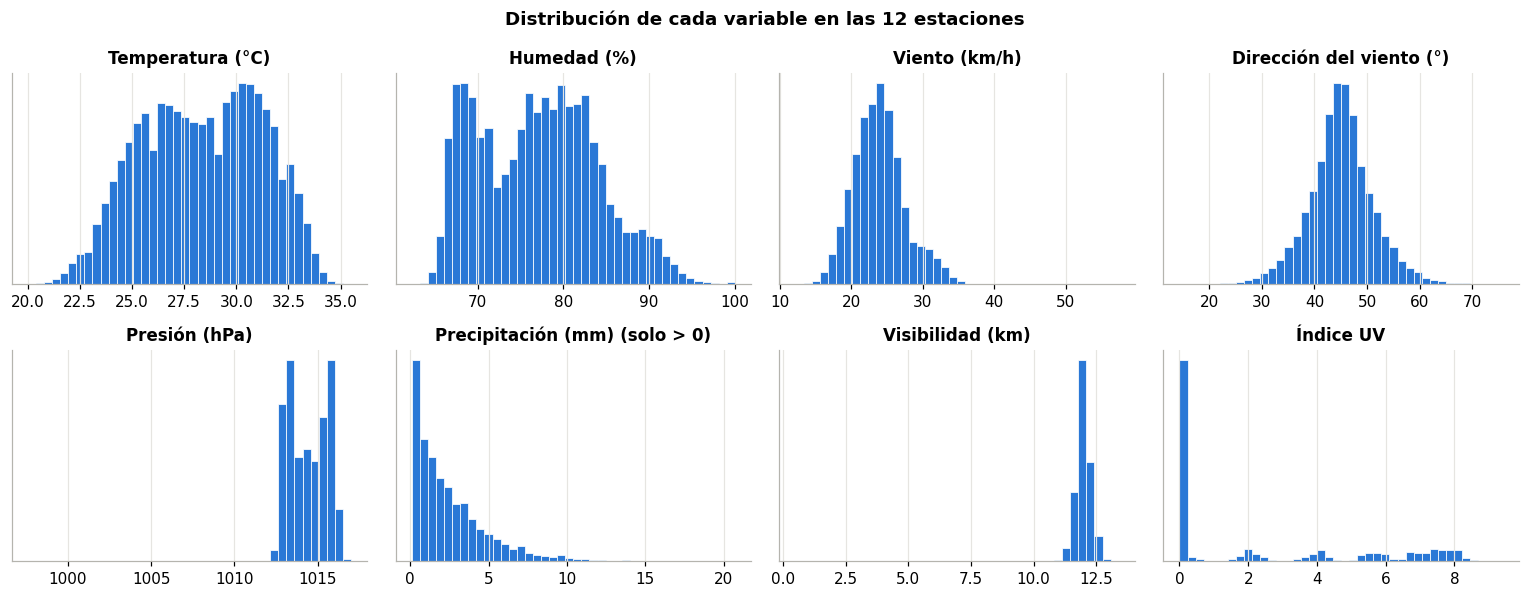

In [5]:
etiquetas = {"temperature_c": "Temperatura (°C)", "humidity_pct": "Humedad (%)", "wind_speed_kmh": "Viento (km/h)",
             "wind_direction_deg": "Dirección del viento (°)", "pressure_hpa": "Presión (hPa)",
             "precipitation_mm": "Precipitación (mm)", "visibility_km": "Visibilidad (km)", "uv_index": "Índice UV"}

fig, ejes = plt.subplots(2, 4, figsize=(14, 5.5))
for eje, var in zip(ejes.flat, VARIABLES):
    datos = lect[var]
    if var == "precipitation_mm":
        datos = datos[datos > 0]          # casi todo es 0; solo miramos cuando llueve
    eje.hist(datos, bins=40, color=AZUL, edgecolor="white", linewidth=0.5)
    eje.set_title(etiquetas[var] + (" (solo > 0)" if var == "precipitation_mm" else ""))
    eje.set_yticks([])
fig.suptitle("Distribución de cada variable en las 12 estaciones", fontweight="bold")
guardar(fig, "01_distribuciones")

La mayoría de las variables se mueven en rangos estrechos, como corresponde a un clima tropical tan estable como el de Aruba. La temperatura media ronda los 28 °C y casi nunca baja de 22 °C; el viento sopla casi siempre del noreste (dirección media de 45°), que es el alisio típico de la zona. La precipitación es prácticamente nula: solo llueve en torno al 0,4 % de las lecturas. El índice UV tiene muchos ceros porque incluye las horas de noche.

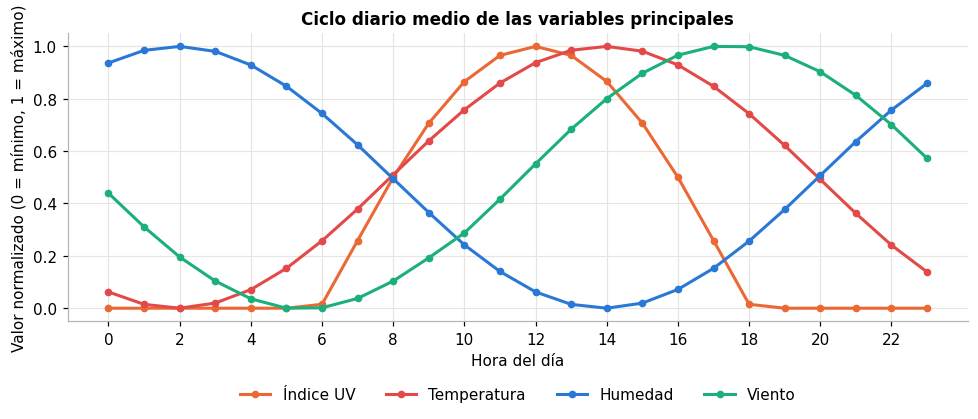

In [6]:
perfil = lect.groupby(lect["timestamp"].dt.hour)[["uv_index", "temperature_c", "humidity_pct", "wind_speed_kmh"]].mean()
normalizado = (perfil - perfil.min()) / (perfil.max() - perfil.min())

fig, eje = plt.subplots(figsize=(9, 4))
colores = {"uv_index": NARANJA, "temperature_c": "#e34948", "humidity_pct": AZUL, "wind_speed_kmh": VERDE}
nombres = {"uv_index": "Índice UV", "temperature_c": "Temperatura", "humidity_pct": "Humedad", "wind_speed_kmh": "Viento"}
for col in normalizado:
    eje.plot(normalizado.index, normalizado[col], color=colores[col], label=nombres[col], marker="o", markersize=4)
eje.set_xticks(range(0, 24, 2))
eje.set_xlabel("Hora del día")
eje.set_ylabel("Valor normalizado (0 = mínimo, 1 = máximo)")
eje.set_title("Ciclo diario medio de las variables principales")
eje.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.18))
guardar(fig, "01_ciclo_diario")

Este gráfico nos sirve para comprobar que la corrección del desfase funcionó. El UV alcanza su máximo a mediodía y la temperatura dos horas después, que es lo que ocurre en la realidad: el suelo y el aire tardan un poco en calentarse. La humedad hace justo lo contrario que la temperatura, y el viento aumenta a lo largo del día y es máximo al final de la tarde.

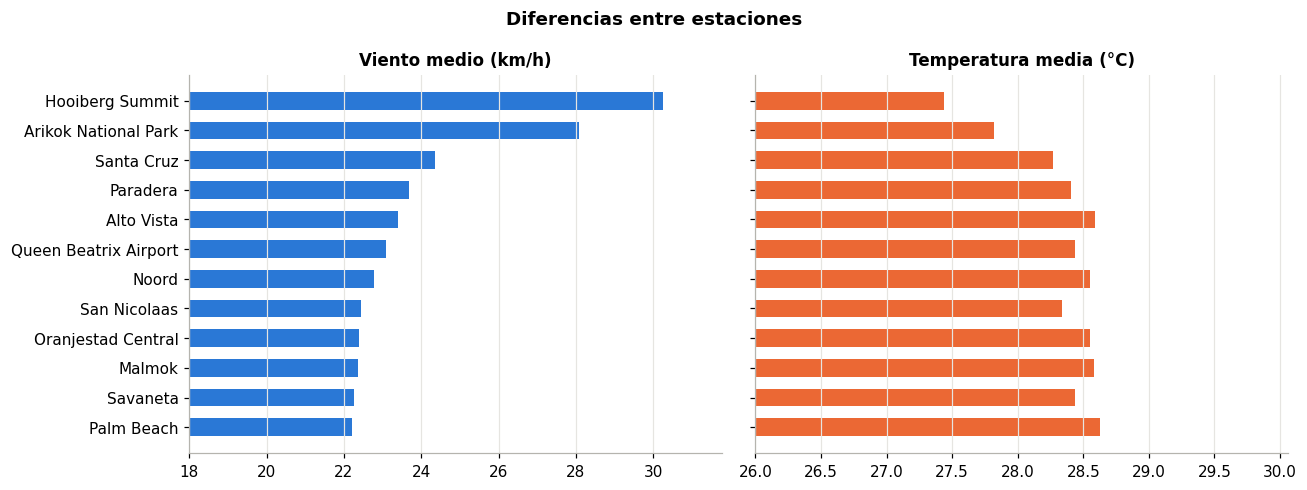

In [7]:
por_estacion = lect.groupby("estacion")[["temperature_c", "wind_speed_kmh", "humidity_pct"]].mean().round(2)
por_estacion = por_estacion.join(estaciones.set_index("name")[["elevation_m", "district"]])
por_estacion.sort_values("wind_speed_kmh").to_csv(TABLAS / "01_medias_por_estacion.csv")

fig, (e1, e2) = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
orden = por_estacion.sort_values("wind_speed_kmh").index
e1.barh(orden, por_estacion.loc[orden, "wind_speed_kmh"], color=AZUL, height=0.6)
e1.set_title("Viento medio (km/h)")
e1.set_xlim(18, None)
e2.barh(orden, por_estacion.loc[orden, "temperature_c"], color=NARANJA, height=0.6)
e2.set_title("Temperatura media (°C)")
e2.set_xlim(26, None)
for eje in (e1, e2):
    eje.grid(axis="y", visible=False)
fig.suptitle("Diferencias entre estaciones", fontweight="bold")
guardar(fig, "01_medias_por_estacion")

Las estaciones se parecen mucho entre sí, salvo dos: Hooiberg Summit y Arikok National Park, que son las que están a más altura (165 y 120 m). En ellas hace algo menos de calor y sopla bastante más viento, alrededor de 30 y 28 km/h frente a los 22–24 km/h del resto. Tiene sentido físicamente y nos confirma que, aunque los datos sean simulados, respetan la geografía de la isla. San Nicolaas, la estación que usamos para el target, está en la media.

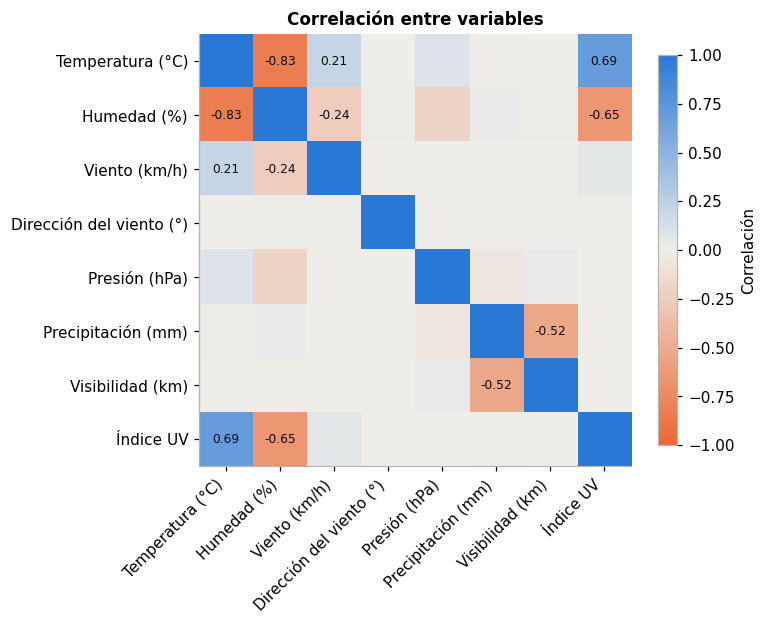

In [8]:
corr = lect[VARIABLES].corr()
corr.round(3).to_csv(TABLAS / "01_correlaciones.csv")

divergente = LinearSegmentedColormap.from_list("div", [NARANJA, "#efeeea", AZUL])
fig, eje = plt.subplots(figsize=(7, 6))
im = eje.imshow(corr, cmap=divergente, vmin=-1, vmax=1)
eje.set_xticks(range(len(VARIABLES)), [etiquetas[v] for v in VARIABLES], rotation=45, ha="right")
eje.set_yticks(range(len(VARIABLES)), [etiquetas[v] for v in VARIABLES])
eje.grid(False)
for i in range(len(VARIABLES)):
    for j in range(len(VARIABLES)):
        valor = corr.iloc[i, j]
        if i != j and abs(valor) >= 0.2:
            eje.text(j, i, f"{valor:.2f}", ha="center", va="center", fontsize=8, color="#0b0b0b")
fig.colorbar(im, ax=eje, shrink=0.8, label="Correlación")
eje.set_title("Correlación entre variables")
guardar(fig, "01_correlaciones")

Las relaciones más fuertes son las que cabía esperar: temperatura y humedad se mueven en sentido contrario (−0,83), y el UV va con la temperatura (0,69) porque los dos dependen del sol. La visibilidad baja cuando llueve. El viento, en cambio, apenas está relacionado con el resto de variables, lo que significa que para predecir la parte eólica del target no vamos a poder apoyarnos mucho en las demás lecturas; tendrá más peso su propio comportamiento reciente.

## 2. Los datos de enriquecimiento

Además de las lecturas, hemos reunido datos externos y públicos sobre Aruba: el calendario de festivos, las llegadas de turistas, las plantas de generación eléctrica y la posición del sol en cada momento. Aquí resumimos los más relevantes.

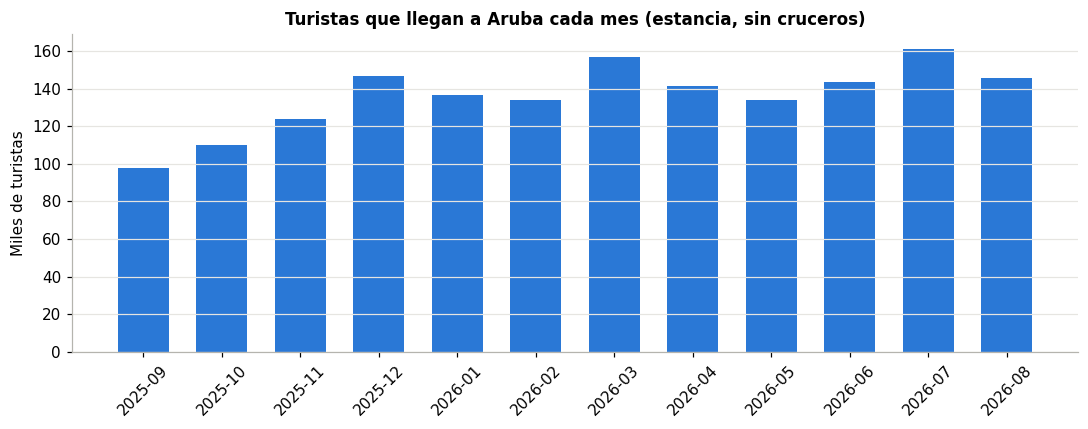

,mes,stopover,var_pct,cruceros_pasajeros
0,2025-09,97778.0,2.6,NaN
1,2025-10,109990.0,5.7,58320.0
2,2025-11,123831.0,15.9,98980.0
3,2025-12,146515.0,14.3,160420.0
4,2026-01,136578.0,9.4,138059.0
5,2026-02,133992.0,NaN,118681.0
6,2026-03,156773.0,8.8,119702.0
7,2026-04,141135.0,11.6,86466.0
8,2026-05,133680.0,14.1,42118.0
9,2026-06,143343.0,13.4,46142.0


In [9]:
turismo = pd.read_csv(ENR / "turismo" / "aruba_turismo_mensual.csv")
t = turismo.dropna(subset=["stopover"])

fig, eje = plt.subplots(figsize=(10, 4))
eje.bar(t["mes"], t["stopover"] / 1000, color=AZUL, width=0.65)
eje.set_ylabel("Miles de turistas")
eje.set_title("Turistas que llegan a Aruba cada mes (estancia, sin cruceros)")
eje.tick_params(axis="x", rotation=45)
eje.grid(axis="x", visible=False)
guardar(fig, "02_turismo_mensual")
t[["mes", "stopover", "var_pct", "cruceros_pasajeros"]]

El turismo es el motor económico de la isla y también un buen indicador del consumo eléctrico, por los hoteles y el aire acondicionado. Entre septiembre de 2025 y agosto de 2026 llegan cada mes entre unos 98.000 y 161.000 turistas, con septiembre como el mes más flojo y marzo y julio como los más fuertes. Todos los meses crecen respecto al año anterior. Ahora mismo no influye en el target, porque la generación renovable depende del clima y no de la gente, pero lo dejamos preparado para cuando incorporemos la demanda al gemelo digital.

In [10]:
calendario = pd.read_csv(ENR / "calendario" / "aruba_calendario_5min.csv", dtype={"festivo_nombre": str})
festivos = calendario.loc[calendario["es_festivo"] == 1, ["fecha_local", "festivo_nombre"]].drop_duplicates()
festivos.to_csv(TABLAS / "02_festivos.csv", index=False)
festivos

,fecha_local,festivo_nombre
33120,2025-12-25,Christmas Day (Pasco di Nacemento)
33408,2025-12-26,Boxing Day (Di dos dia di Pasco di Nacemento)
35136,2026-01-01,New Year's Day (Aña Nobo)
42048,2026-01-25,Betico Croes Day (Dia di Betico)
48384,2026-02-16,Carnival Monday (Dialuna di Carnaval)
57024,2026-03-18,National Anthem and Flag Day (Dia di Himno y B...
61632,2026-04-03,Good Friday (Bierna Santo)
62496,2026-04-06,Easter Monday (Di dos dia di Pasco)
68544,2026-04-27,King's Day (Dia di Rey)
69696,2026-05-01,Labour Day (Dia di Obrero)


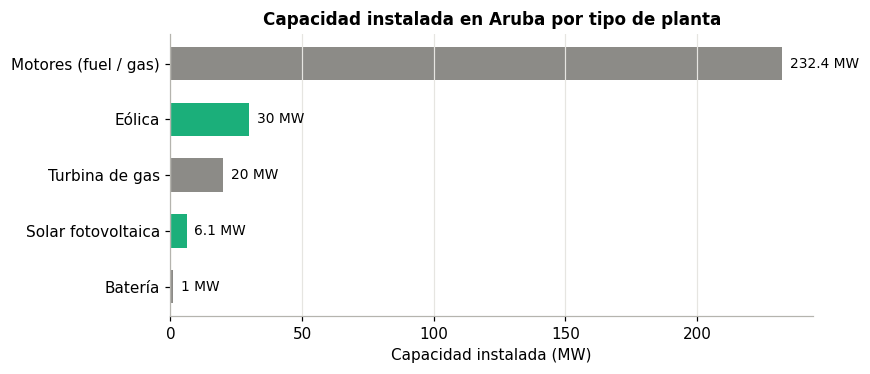

In [11]:
sistema = pd.read_csv(ENR / "sistema_electrico" / "aruba_sistema_electrico.csv")
tipos = {"termica_motores": "Motores (fuel / gas)", "termica_turbina_gas": "Turbina de gas",
         "eolica": "Eólica", "solar_fv": "Solar fotovoltaica", "almacenamiento": "Batería"}
capacidad = sistema.assign(tipo=sistema["tipo"].map(tipos)).groupby("tipo")["capacidad_mw"].sum().sort_values()
capacidad.to_csv(TABLAS / "02_capacidad_por_tipo.csv")

fig, eje = plt.subplots(figsize=(8, 3.5))
colores = [VERDE if t in ("Eólica", "Solar fotovoltaica") else GRIS for t in capacidad.index]
eje.barh(capacidad.index, capacidad.values, color=colores, height=0.6)
for y, valor in enumerate(capacidad.values):
    eje.text(valor + 3, y, f"{valor:g} MW", va="center", fontsize=9)
eje.set_xlabel("Capacidad instalada (MW)")
eje.set_title("Capacidad instalada en Aruba por tipo de planta")
eje.grid(axis="y", visible=False)
guardar(fig, "02_capacidad_instalada")

De los casi 290 MW instalados en la isla, solo 36,1 MW son renovables: el parque eólico Vader Piet (30 MW) y el Sunrise Solar Park (6,1 MW). El resto son motores y una turbina de gas. Esto da una idea de la escala del problema: aunque la renovable trabajara a pleno rendimiento, no llegaría a cubrir ni un tercio de la demanda media prevista para 2026, que es de unos 121 MW. Por eso el despacho siempre va a necesitar la parte térmica, y lo que aporta predecir bien la renovable es saber cuánto hay que pedirle a los motores en cada momento.

## 3. Datos simulados frente a datos reales

Como las lecturas de la asignatura son simuladas, quisimos comprobar hasta qué punto se parecen al clima real de Aruba. Para ello descargamos de Open-Meteo los datos meteorológicos de las mismas coordenadas y fechas (script `descargar_meteo_real.py`) y los cruzamos con nuestras lecturas, instante a instante y estación por estación.

Open-Meteo no son medidas de un sensor, sino el resultado de un modelo meteorológico, pero es lo más parecido a datos reales que tenemos disponible para todo el periodo.

In [12]:
real = pd.read_csv(ENR / "clima_solar" / "aruba_meteo_real_5min.csv.gz")
vader_piet = real[real["station_id"] == "VADER_PIET"].set_index("timestamp")
real = real[real["station_id"] != "VADER_PIET"]

lect["clave"] = lect["timestamp"].dt.strftime("%Y-%m-%dT%H:%M:%SZ")
cruce = lect.merge(real, left_on=["station_id", "clave"], right_on=["station_id", "timestamp"],
                   suffixes=("", "_real"))
print(f"Lecturas cruzadas con Open-Meteo: {len(cruce):,} de {len(lect):,}")

PARES = [("temperature_c", "temperature_2m", "Temperatura (°C)"),
         ("humidity_pct", "relative_humidity_2m", "Humedad (%)"),
         ("wind_speed_kmh", "wind_speed_10m", "Viento a 10 m (km/h)"),
         ("pressure_hpa", "surface_pressure", "Presión (hPa)")]

filas = []
for sim, rea, nombre in PARES:
    filas.append({"variable": nombre,
                  "media simulada": cruce[sim].mean(), "media real": cruce[rea].mean(),
                  "desv. simulada": cruce[sim].std(), "desv. real": cruce[rea].std(),
                  "correlación": cruce[sim].corr(cruce[rea]),
                  "error medio absoluto": (cruce[sim] - cruce[rea]).abs().mean()})
# La lluvia de Open-Meteo es un total horario repetido en cada fila de 5 minutos
filas.append({"variable": "Lluvia anual (mm)",
              "media simulada": cruce["precipitation_mm"].mean() * 288 * 365,
              "media real": cruce["precipitation"].mean() * 24 * 365})
comparacion = pd.DataFrame(filas).set_index("variable").round(2)
comparacion.to_csv(TABLAS / "03_comparacion_simulado_real.csv")
comparacion

Lecturas cruzadas con Open-Meteo: 1,287,072 de 1,287,072


,media simulada,media real,desv. simulada,desv. real,correlación,error medio absoluto
variable,,,,,,
Temperatura (°C),28.34,28.21,2.86,1.64,0.60,1.87
Humedad (%),76.99,73.34,6.91,7.97,0.47,6.67
Viento a 10 m (km/h),23.94,27.85,3.77,6.05,0.06,6.62
Presión (hPa),1014.38,1009.79,1.34,2.48,0.14,4.66
Lluvia anual (mm),1145.27,367.19,NaN,NaN,NaN,NaN


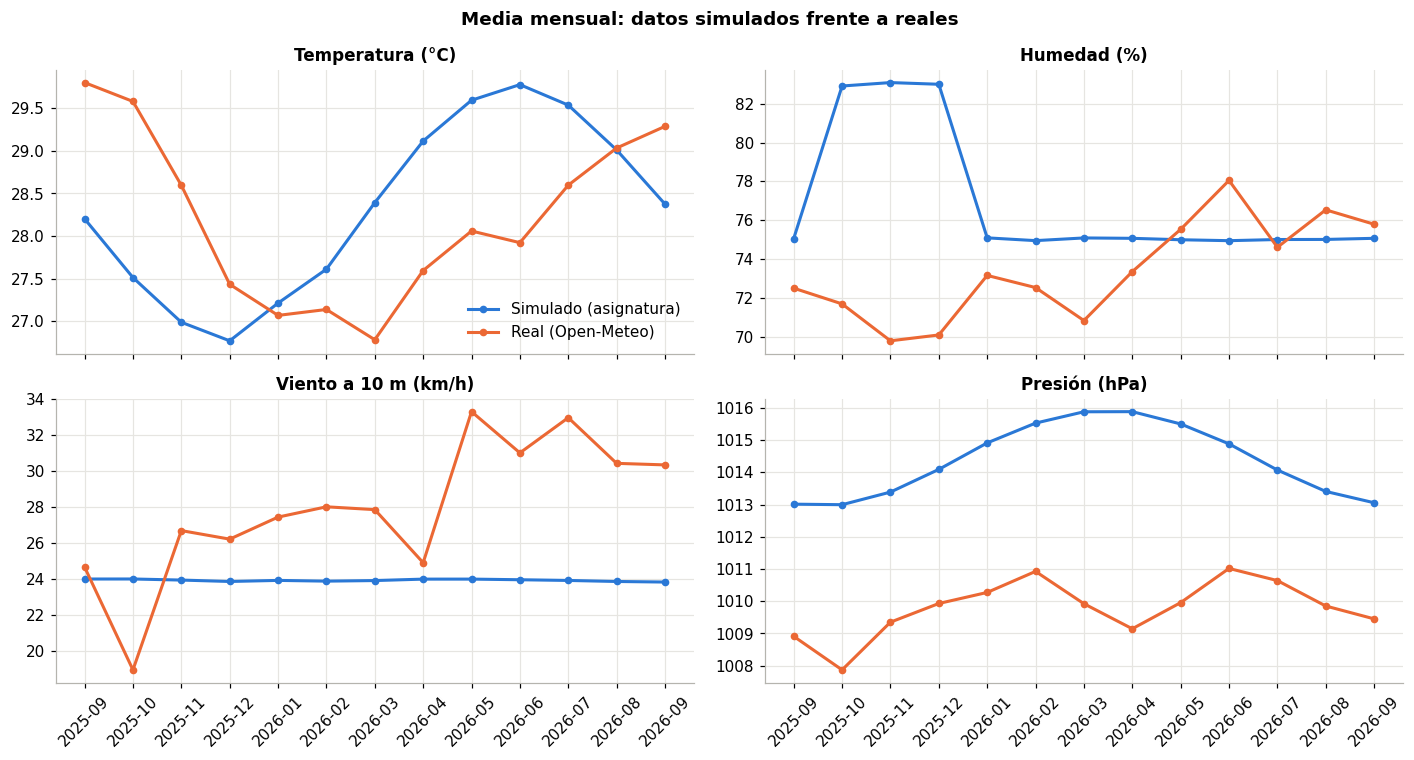

In [13]:
mensual = cruce.groupby(cruce["timestamp"].dt.strftime("%Y-%m"))[[c for p in PARES for c in p[:2]]].mean()

fig, ejes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
for eje, (sim, rea, nombre) in zip(ejes.flat, PARES):
    eje.plot(mensual.index, mensual[sim], color=AZUL, marker="o", markersize=4, label="Simulado (asignatura)")
    eje.plot(mensual.index, mensual[rea], color=NARANJA, marker="o", markersize=4, label="Real (Open-Meteo)")
    eje.set_title(nombre)
    eje.tick_params(axis="x", rotation=45)
ejes[0, 0].legend(frameon=False)
fig.suptitle("Media mensual: datos simulados frente a reales", fontweight="bold")
guardar(fig, "03_simulado_vs_real_mensual")

Aquí aparece la diferencia más importante entre los datos simulados y los reales: **la estacionalidad**. En la realidad, el viento en Aruba cambia mucho a lo largo del año. Es más flojo en otoño (unos 19 km/h en octubre) y muy fuerte entre mayo y julio, cuando soplan con más intensidad los alisios (más de 30 km/h). En los datos simulados el viento medio es prácticamente el mismo todos los meses, unos 24 km/h, así que esa variación desaparece.

Con la temperatura ocurre algo parecido pero al revés de lo esperable. En los datos simulados los meses más calurosos son mayo y junio, mientras que en la realidad el calor máximo llega en septiembre y octubre, al final de la estación seca.

La humedad simulada tiene un comportamiento curioso: de octubre a diciembre de 2025 sube de golpe unos 8 puntos (del 75 % al 83 %) y el 1 de enero vuelve de un día para otro al 75 %, donde se queda fija el resto del año. Coincide con la temporada de lluvias de Aruba, así que suponemos que quien generó los datos la simuló como un escalón. En los datos reales la humedad cambia de forma más gradual y no sigue ese patrón.

La lluvia también difiere bastante: los datos simulados suman unos 1.150 mm al año, mientras que Open-Meteo da unos 370 mm, que se acerca más a lo que se conoce del clima de la isla (en torno a 400–450 mm anuales).

La presión simulada sale unos 4–5 hPa más alta que la real. Esto no es un error, sino que se miden cosas distintas: la de nuestras lecturas está referida al nivel del mar y la de Open-Meteo es la presión en superficie, que baja con la altitud.

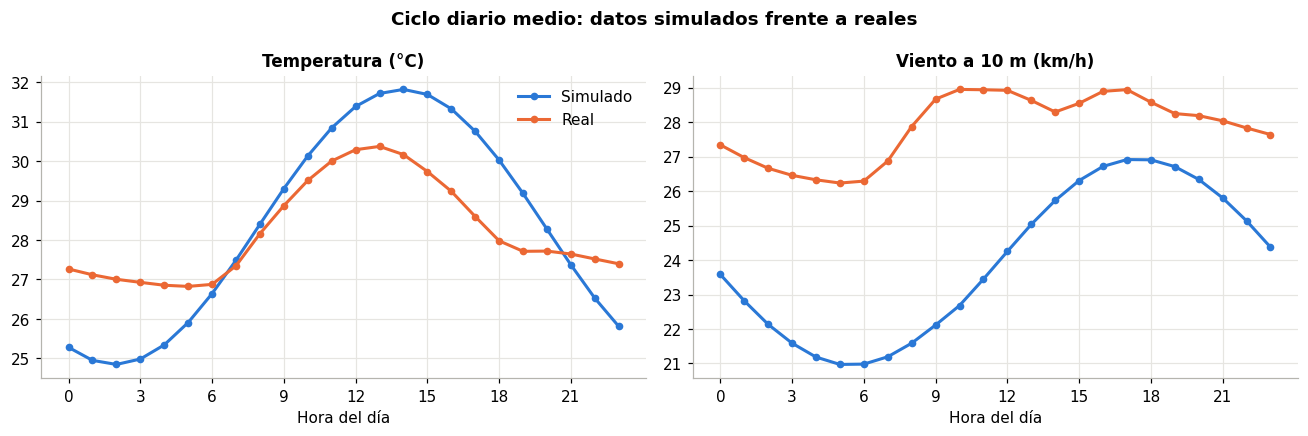

In [14]:
fig, (e1, e2) = plt.subplots(1, 2, figsize=(12, 4))
for eje, (sim, rea, nombre) in zip((e1, e2), [PARES[0], PARES[2]]):
    diario = cruce.groupby(cruce["timestamp"].dt.hour)[[sim, rea]].mean()
    eje.plot(diario.index, diario[sim], color=AZUL, marker="o", markersize=4, label="Simulado")
    eje.plot(diario.index, diario[rea], color=NARANJA, marker="o", markersize=4, label="Real")
    eje.set_title(nombre)
    eje.set_xlabel("Hora del día")
    eje.set_xticks(range(0, 24, 3))
e1.legend(frameon=False)
fig.suptitle("Ciclo diario medio: datos simulados frente a reales", fontweight="bold")
guardar(fig, "03_simulado_vs_real_diario")

En el ciclo diario los datos simulados se comportan mejor. La temperatura sube y baja a las mismas horas que la real (máximo hacia las 13–14 h), aunque con una amplitud mayor: el día simulado es más caluroso y la noche más fresca de lo que es en realidad. El viento real también es más fuerte por la tarde, igual que en la simulación, pero con una media más alta (28 km/h frente a 24 km/h).

En resumen, los datos simulados reproducen bien el día tipo, pero no la evolución a lo largo del año ni la variabilidad real. La correlación instante a instante entre el viento simulado y el real es prácticamente cero (0,06), lo que quiere decir que los episodios concretos de mucho o poco viento no coinciden.

## 4. Lo que falta

Hasta aquí hemos revisado los datos de partida, el enriquecimiento y su parecido con el clima real. Queda la segunda mitad del análisis, centrada en la variable objetivo. Dejamos indicados los apartados y lo que hay que hacer en cada uno para repartirlos en el grupo.

**4.1 Validación con datos reales de producción.** En `DatosEnriquecimiento/sistema_electrico/web_real_20251228_15min.csv` tenemos la producción eólica real y la demanda de la isla del 27 al 28 de diciembre de 2025. Hay que comparar esa producción con la `P_eolica_MW` del dataset para los mismos instantes, y también con la que sale al aplicar la misma curva de potencia (función `potencia_eolica` de `calcular_target.py`) al viento real a 80 m de Open-Meteo en Vader Piet.

**4.2 Distribución del target.** Histograma de `P_renovable_MW` y estadísticas de la eólica, la solar y el total, incluido el factor de capacidad de cada una (media dividida entre 30 MW, 6,1 MW y 36,1 MW).

**4.3 Ciclo diario y mensual del target.** Generación media por hora y por mes, separando eólica y solar, para ver cuándo se genera más y si hay diferencias a lo largo del año.

**4.4 Relación de las entradas con el target.** Correlación de cada variable con `target_P_renovable_t+1h`, dejando fuera `P_eolica_MW`, `P_solar_MW`, `P_renovable_MW` y `P_renovable_media_1h`, porque contienen el target del mismo instante.

**4.5 Autocorrelación.** Cuánto se parece la generación a la de 1 h, 12 h y 24 h antes. Sirve para justificar los retardos y el modelo de referencia por persistencia.

**4.6 Conclusiones del EDA** y decisiones para la fase de modelos: modelo de referencia, separación de entrenamiento y prueba por fechas y qué variables usar.

Las figuras y tablas de estos apartados deben guardarse con la función `guardar()` y en la carpeta `TABLAS`, siguiendo la numeración `04_...`, para que queden junto al resto en `resultados/04_eda/`.

### 4.1 Validación con datos reales de producción

*Pendiente.*

In [15]:
# Pendiente

### 4.2 Distribución del target

*Pendiente.*

In [16]:
# Pendiente

### 4.3 Ciclo diario y mensual del target

*Pendiente.*

In [17]:
# Pendiente

### 4.4 Relación de las entradas con el target

*Pendiente.*

In [18]:
# Pendiente

### 4.5 Autocorrelación

*Pendiente.*

In [19]:
# Pendiente

### 4.6 Conclusiones

*Pendiente.*